# Pharma Sales Visualization: 2015 vs 2016
**Author:** Amal Shesnij

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.float_format', '{:,.2f}'.format)

sales = pd.read_csv('SalesData.csv')
print(sales.shape)
print('Missing values:', sales.isnull().sum().sum())
sales.head()

(3709, 14)
Missing values: 0


,AccountId,AccountName,Region,Division,City,State,Tier,Month,Sales2015,Sales2016,Units2015,Units2016,TargetAchevied2015,TargetAchevied2016
0,1116,Account1,West,DIAMONDBACK,PHOENIX W,AZ,Low,Aug,0.00,"13,208.52",0.00,4.00,0.70,1.53
1,1116,Account1,West,DIAMONDBACK,PHOENIX W,AZ,Low,Oct,"10,500.78","23,114.91",3.00,7.00,0.84,1.31
2,2391,Account2,East,MINUTEMEN,HARTFORD,CT,Med,Jun,0.00,"6,627.00",0.00,3.00,1.15,1.29
3,2391,Account2,East,MINUTEMEN,HARTFORD,CT,Med,Mar,"19,881.00","13,254.00",9.00,6.00,1.33,1.17
4,2397,Account3,East,MINUTEMEN,WORCESTER,MA,Med,Sep,"3,684.48",0.00,1.00,0.00,1.02,1.53


## Q1. Sales by region: 2015 vs 2016

,Sales2015,Sales2016,Growth %
Region,,,
Central,"7,891,728.86","9,787,808.73",24.00
East,"9,512,916.49","12,667,230.45",33.20
West,"5,349,744.64","7,209,689.43",34.80


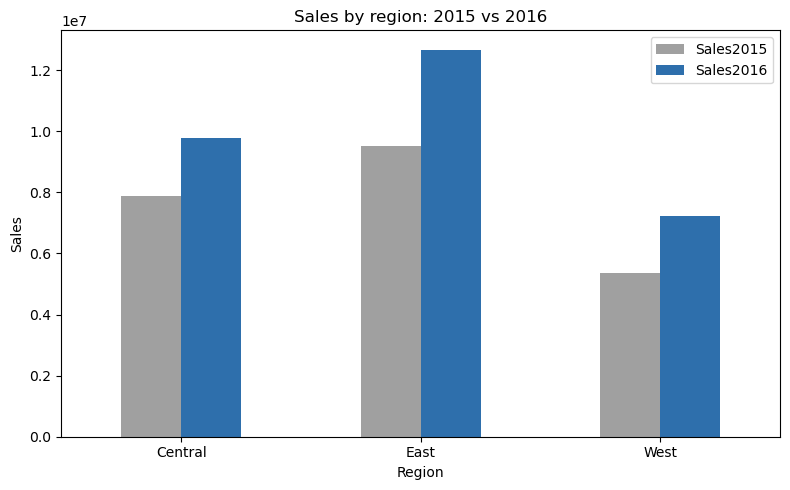

In [2]:
region = sales.groupby('Region')[['Sales2015', 'Sales2016']].sum()
region['Growth %'] = ((region['Sales2016'] / region['Sales2015'] - 1) * 100).round(1)
display(region)

region[['Sales2015', 'Sales2016']].plot(kind='bar', figsize=(8, 5), color=['#A0A0A0', '#2E6FAC'])
plt.title('Sales by region: 2015 vs 2016'); plt.ylabel('Sales'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## Q2. Share of 2016 sales by region

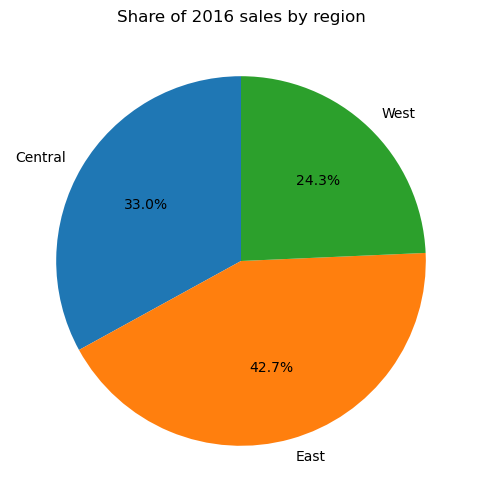

In [3]:
region['Sales2016'].plot(kind='pie', autopct='%1.1f%%', figsize=(6, 6), ylabel='', startangle=90)
plt.title('Share of 2016 sales by region'); plt.show()

**Conclusion (Q1–Q2):** All three regions grew in 2016. East is the largest region, with 42.7% of 2016 sales, followed by Central (33.0%) and West (24.3%). West is the smallest region but grew the fastest (+34.8%), ahead of East (+33.2%) and Central (+24.0%).

## Q3. Sales by region and tier

Sales2015    Sales2016
Region  Tier                          
Central High 4,798,698.43 6,026,042.94
        Low    943,439.67 1,132,832.85
        Med  2,068,225.87 2,632,181.47
        Out     81,364.89    -3,248.53
East    High 6,102,946.12 7,817,151.10
        Low    901,665.80 1,144,929.59
        Med  2,470,998.02 3,705,149.76
        Out     37,306.55         0.00
West    High 2,944,789.26 3,768,038.35
        Low    671,064.38 1,099,502.18
        Med  1,718,475.92 2,342,148.90
        Out     15,415.08         0.00

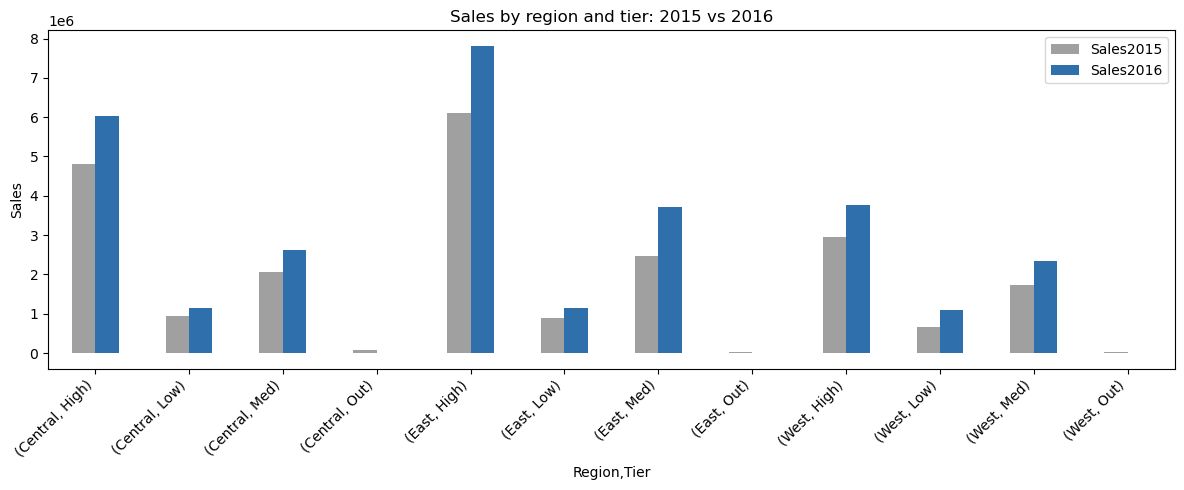

In [4]:
region_tier = sales.groupby(['Region', 'Tier'])[['Sales2015', 'Sales2016']].sum()
display(region_tier)

region_tier.plot(kind='bar', figsize=(12, 5), color=['#A0A0A0', '#2E6FAC'])
plt.title('Sales by region and tier: 2015 vs 2016'); plt.ylabel('Sales')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

## Q4. East region: states with lower sales in 2016

,Sales2015,Sales2016,Change
State,,,
CT,"197,202.79","323,502.31","126,299.52"
DC,"216,723.95","257,421.69","40,697.74"
FL,"1,660,162.00","2,508,232.28","848,070.28"
GA,"681,546.46","946,919.77","265,373.31"
MA,"419,278.75","687,096.45","267,817.70"
MD,"527,309.06","750,008.79","222,699.73"
ME,"77,425.64","183,673.05","106,247.41"
NC,"1,292,801.64","1,610,521.00","317,719.36"
NH,"136,419.38","144,717.51","8,298.13"


States with a decline: ['NY']


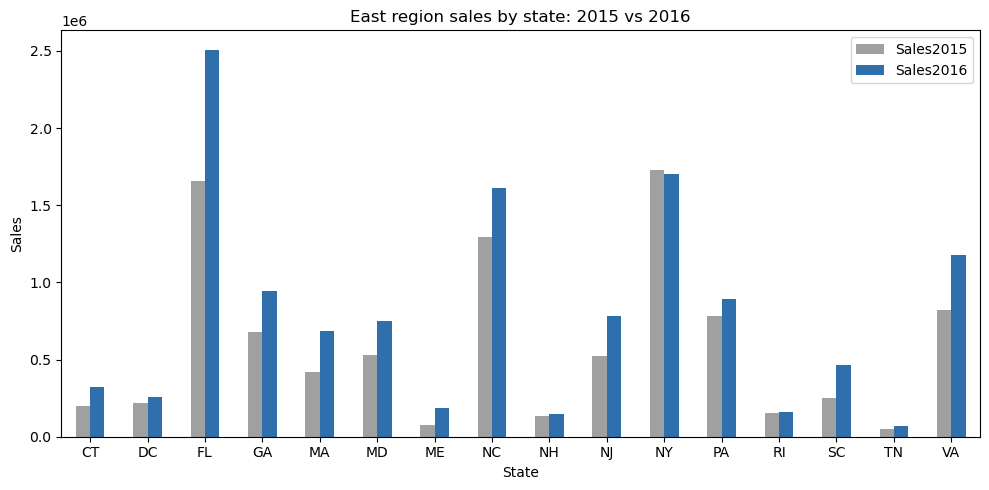

In [5]:
east = sales[sales['Region'] == 'East'].groupby('State')[['Sales2015', 'Sales2016']].sum()
east['Change'] = east['Sales2016'] - east['Sales2015']
display(east)

print('States with a decline:', east[east['Change'] < 0].index.tolist())

east[['Sales2015', 'Sales2016']].plot(kind='bar', figsize=(10, 5), color=['#A0A0A0', '#2E6FAC'])
plt.title('East region sales by state: 2015 vs 2016'); plt.ylabel('Sales'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## Q5. High tier: divisions with fewer units in 2016

In [6]:
high = sales[sales['Tier'] == 'High'].groupby('Division')[['Units2015', 'Units2016']].sum()
high['Change'] = high['Units2016'] - high['Units2015']
print('Divisions with a decline:', high[high['Change'] < 0].index.tolist())
high.sort_values('Change')

Divisions with a decline: []


,Units2015,Units2016,Change
Division,,,
NORDIC,210.17,225.83,15.67
WOLVERINE,122.00,143.00,21.00
REVOLUTION,205.83,226.83,21.00
DIAMONDBACK,153.33,176.67,23.33
NORTHWEST,135.50,163.67,28.17
KINETIC,214.33,244.50,30.17
GRIDIRON,213.67,246.17,32.50
EMPIRE,414.33,449.33,35.00
RIPTIDE,147.50,183.83,36.33


**Conclusion (Q3–Q5):**
- The High tier is the largest in every region and grew in all three. The "Out" tier is negligible, and in Central it is slightly negative in 2016 (−3,249), most likely due to returns or credit notes.
- In the East region, only **New York (NY)** declined, slightly, from 1.73M to 1.70M.
- In the High tier, **no division** sold fewer units in 2016; every division grew, led by Wave Rider (+49.8 units).

## Q6. Quarter column

In [7]:
quarter_map = {'Jan': 'Q1', 'Feb': 'Q1', 'Mar': 'Q1',
               'Apr': 'Q2', 'May': 'Q2', 'Jun': 'Q2',
               'Jul': 'Q3', 'Aug': 'Q3', 'Sep': 'Q3',
               'Oct': 'Q4', 'Nov': 'Q4', 'Dec': 'Q4'}
sales['Qtr'] = sales['Month'].map(quarter_map)

print('Unmapped months:', sales['Qtr'].isnull().sum())
sales[['Month', 'Qtr']].drop_duplicates().sort_values('Qtr')

Unmapped months: 0


,Month,Qtr
3,Mar,Q1
6,Feb,Q1
31,Jan,Q1
2,Jun,Q2
18,Apr,Q2
22,May,Q2
0,Aug,Q3
4,Sep,Q3
5,Jul,Q3
1,Oct,Q4


## Q7. Quarterly sales: 2015 vs 2016

,Sales2015,Sales2016
Qtr,,
Q1,"5,485,800.16","6,997,953.24"
Q2,"5,390,862.08","7,237,361.17"
Q3,"6,164,093.84","7,861,546.02"
Q4,"5,713,633.91","7,567,868.17"


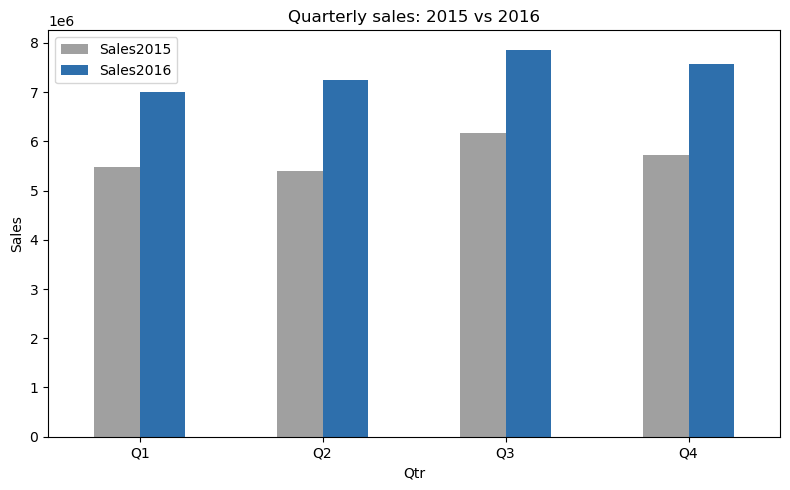

In [8]:
qtr = sales.groupby('Qtr')[['Sales2015', 'Sales2016']].sum()
display(qtr)
qtr.plot(kind='bar', figsize=(8, 5), color=['#A0A0A0', '#2E6FAC'])
plt.title('Quarterly sales: 2015 vs 2016'); plt.ylabel('Sales'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## Q8. 2016 sales composition by tier, per quarter

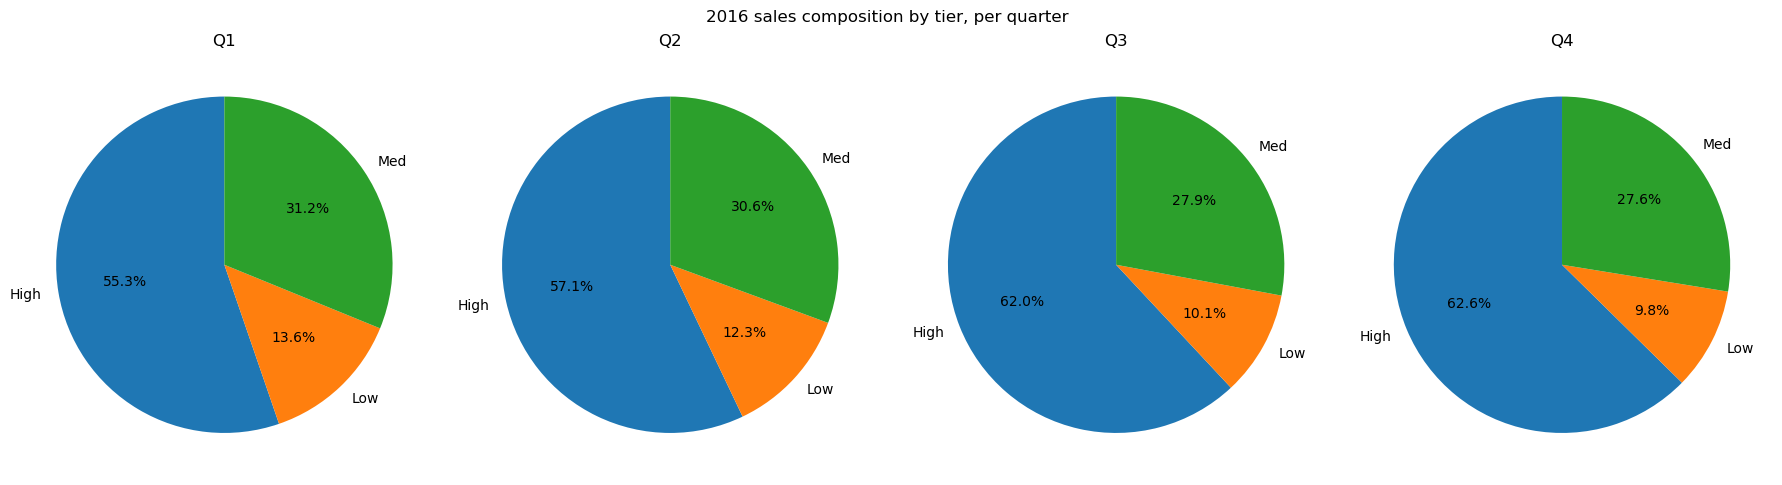

In [9]:
tier_qtr = sales.pivot_table(index='Tier', columns='Qtr', values='Sales2016', aggfunc='sum')
tier_qtr = tier_qtr.drop('Out')   # near-zero and slightly negative; a pie chart cannot show negatives

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, q in zip(axes, tier_qtr.columns):
    ax.pie(tier_qtr[q], labels=tier_qtr.index, autopct='%1.1f%%', startangle=90)
    ax.set_title(q)
plt.suptitle('2016 sales composition by tier, per quarter')
plt.tight_layout(); plt.show()

**Conclusion (Q6–Q8):**
- A quarter column was created by mapping months to Q1–Q4 (a dictionary with `.map()` is clearer than nested `np.where` for four categories).
- 2016 sales were higher than 2015 in every quarter, and Q3 was the strongest quarter in both years.
- The High tier's share of 2016 sales rose every quarter, from 55.3% in Q1 to 62.6% in Q4, while the Low and Medium tiers' shares fell. Growth is increasingly driven by high-tier customers.
- The "Out" tier was excluded from the pie charts because it is close to zero and slightly negative.

## Key Findings
1. All regions grew in 2016; East is the largest (42.7% of sales), and West grew fastest (+34.8%).
2. The High tier is the largest in every region.
3. In the East region, only New York declined (slightly).
4. No High-tier division saw a drop in units.
5. 2016 beat 2015 in every quarter; Q3 is the strongest quarter.
6. High-tier customers make up a growing share of sales each quarter (55% → 63%).